# Few-Shot Online BNN Surrogate Learning

This notebook simulates online learning over the cached BCLF Touchstone dataset. It starts from a small random training set, trains the dB BNN surrogate, then adds one new cached sample per iteration and warm-starts the same model for a small number of epochs.

In [1]:
from pathlib import Path
import csv
import importlib
import inspect
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import modeling.bclf_dataset as bclf_dataset_module
import modeling.legacy_bnn_surrogate as legacy_bnn_module
importlib.reload(bclf_dataset_module)
importlib.reload(legacy_bnn_module)

BCLFTouchstoneDatasetLoader = bclf_dataset_module.BCLFTouchstoneDatasetLoader
LegacyBNNResponseSurrogate = legacy_bnn_module.LegacyBNNResponseSurrogate
response_db = bclf_dataset_module.response_db

if "update" not in dir(LegacyBNNResponseSurrogate):
    raise RuntimeError("Loaded LegacyBNNResponseSurrogate without warm-start update support. Restart kernel and rerun.")
if "target_mode" not in inspect.signature(LegacyBNNResponseSurrogate.__init__).parameters:
    raise RuntimeError("Loaded LegacyBNNResponseSurrogate without dB target support. Restart kernel and rerun.")

from optimization.optimization_spec import BCLFOptimizationSpec


In [2]:
def build_default_bclf_spec():
    return BCLFOptimizationSpec(
        passband_ghz=(4.8, 5.4),
        lower_stopband_ghz=(3.6, 4.4),
        upper_stopband_ghz=(5.8, 8.7),
        min_passband_s21_db=-5.0,
        max_passband_s11_db=-7.0,
        max_stopband_s21_db=-15.0,
        s11_weight=0.5,
        stopband_weight=0.5,
    )


def write_csv(path, rows):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not rows:
        path.write_text("", encoding="utf-8")
        return
    fieldnames = sorted({key for row in rows for key in row.keys()})
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)


def column(rows, name):
    return np.asarray([float(row[name]) for row in rows], dtype=float)


def show_rows(rows, limit=5):
    display(rows[:limit] if isinstance(rows, list) else rows)


def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a, dtype=float) - np.asarray(b, dtype=float)) ** 2)))


def rankdata(values):
    order = np.argsort(values)
    ranks = np.empty(len(values), dtype=float)
    ranks[order] = np.arange(len(values), dtype=float)
    return ranks


def spearman(a, b):
    if len(a) < 2:
        return float("nan")
    ra = rankdata(np.asarray(a, dtype=float))
    rb = rankdata(np.asarray(b, dtype=float))
    if np.std(ra) < 1e-12 or np.std(rb) < 1e-12:
        return float("nan")
    return float(np.corrcoef(ra, rb)[0, 1])


def topk_recall(true_values, predicted_values, k):
    if k <= 0:
        return float("nan")
    true_top = set(np.argsort(true_values)[:k].tolist())
    pred_top = set(np.argsort(predicted_values)[:k].tolist())
    return float(len(true_top & pred_top) / k)


def evaluate_objectives(dataset, spec, indices, sparams=None):
    values = []
    source = dataset.s_params if sparams is None else sparams
    if sparams is None:
        for idx in indices:
            values.append(spec.evaluate(dataset.freqs, source[int(idx)]).scalar_objective())
    else:
        for row in source:
            values.append(spec.evaluate(dataset.freqs, row).scalar_objective())
    return np.asarray(values, dtype=float)


def evaluate_split(dataset, spec, model, indices, split_name, iteration, num_train_samples, cumulative_epochs, mc_samples):
    indices = np.asarray(indices, dtype=int)
    if len(indices) == 0:
        return None, None
    pred = model.predict_s_params(dataset, indices, mc_samples=mc_samples)
    true = dataset.s_params[indices]
    true_obj = evaluate_objectives(dataset, spec, indices)
    pred_obj = evaluate_objectives(dataset, spec, indices, sparams=pred)
    row = {
        "iteration": int(iteration),
        "split": split_name,
        "num_train_samples": int(num_train_samples),
        "cumulative_epochs": int(cumulative_epochs),
        "num_eval_samples": int(len(indices)),
        "s11_db_mae": mae(response_db(true, 0, 0), response_db(pred, 0, 0)),
        "s11_db_rmse": rmse(response_db(true, 0, 0), response_db(pred, 0, 0)),
        "s21_db_mae": mae(response_db(true, 1, 0), response_db(pred, 1, 0)),
        "s21_db_rmse": rmse(response_db(true, 1, 0), response_db(pred, 1, 0)),
        "objective_mae": mae(true_obj, pred_obj),
        "objective_rmse": rmse(true_obj, pred_obj),
        "objective_spearman": spearman(true_obj, pred_obj),
        "top10_recall": topk_recall(true_obj, pred_obj, k=min(10, len(true_obj))),
    }
    pred_rows = [
        {
            "iteration": int(iteration),
            "split": split_name,
            "dataset_index": int(idx),
            "case_id": dataset.case_ids[int(idx)],
            "true_objective": float(t),
            "pred_objective": float(p),
            "abs_objective_error": float(abs(t - p)),
        }
        for idx, t, p in zip(indices, true_obj, pred_obj)
    ]
    return row, {"indices": indices, "pred_sparams": pred, "prediction_rows": pred_rows}


## Settings

In [3]:
EXPERIMENT_MODE = "full"  # "full" or "smoke"
TARGET_MODE = "db"
SEED = 0

DATASET_DIR = ROOT / "data" / "bandpass_coupled_line_filter_export" / "ext"
OUTPUT_DIR = ROOT / "experiments" / "bnn_bclf_fewshot_online_learning"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if EXPERIMENT_MODE == "full":
    INITIAL_SAMPLES = 8
    NUM_UPDATES = 40
    INITIAL_EPOCHS = 400
    UPDATE_EPOCHS = 10
    TEST_FRACTION = 0.2
    BNN_KWARGS = {
        "epochs": INITIAL_EPOCHS,
        "batch_size": 1024,
        "lr": 1e-3,
        "bayesian_loss_weight": 1e-4,
        "mc_samples": 50,
        "hidden_dims": [256, 256, 256],
        "target_mode": TARGET_MODE,
        "device": "cuda" if torch.cuda.is_available() else "cpu",
    }
else:
    INITIAL_SAMPLES = 3
    NUM_UPDATES = 2
    INITIAL_EPOCHS = 1
    UPDATE_EPOCHS = 1
    TEST_FRACTION = 0.2
    BNN_KWARGS = {
        "epochs": INITIAL_EPOCHS,
        "batch_size": 64,
        "lr": 1e-3,
        "bayesian_loss_weight": 1e-4,
        "mc_samples": 2,
        "hidden_dims": [16],
        "target_mode": TARGET_MODE,
        "device": "cpu",
    }

EVAL_MC_SAMPLES = BNN_KWARGS["mc_samples"]
SAVE_EVERY_ITERATION_MODEL = False
FINAL_MODEL_PATH = OUTPUT_DIR / f"fewshot_bnn_{TARGET_MODE}_seed{SEED}_final.pt"
CONFIG_PATH = OUTPUT_DIR / "fewshot_config.json"
METRICS_PATH = OUTPUT_DIR / "fewshot_metrics.csv"
TRACE_PATH = OUTPUT_DIR / "fewshot_selected_trace.csv"
PREDICTION_ROWS_PATH = OUTPUT_DIR / "fewshot_prediction_rows.csv"
PREDICTION_CACHE_PATH = OUTPUT_DIR / "fewshot_prediction_cache.npz"

print("device", BNN_KWARGS["device"])


device cuda


## Load Dataset And Split

In [4]:
dataset = BCLFTouchstoneDatasetLoader(dataset_dir=DATASET_DIR).load()
spec = build_default_bclf_spec()
rng = np.random.default_rng(SEED)
all_indices = np.arange(dataset.n_samples)
shuffled = rng.permutation(all_indices)
test_size = max(1, int(round(dataset.n_samples * TEST_FRACTION)))
test_indices = np.sort(shuffled[:test_size])
online_pool = shuffled[test_size:].tolist()
initial_train_indices = sorted(int(i) for i in online_pool[:INITIAL_SAMPLES])
remaining_pool = [int(i) for i in online_pool[INITIAL_SAMPLES:]]
num_updates = min(NUM_UPDATES, len(remaining_pool))

config = {
    "experiment_mode": EXPERIMENT_MODE,
    "seed": SEED,
    "target_mode": TARGET_MODE,
    "initial_samples": INITIAL_SAMPLES,
    "num_updates_requested": NUM_UPDATES,
    "num_updates": num_updates,
    "initial_epochs": INITIAL_EPOCHS,
    "update_epochs": UPDATE_EPOCHS,
    "test_fraction": TEST_FRACTION,
    "bnn_kwargs": BNN_KWARGS,
    "initial_train_indices": initial_train_indices,
    "test_indices": test_indices.tolist(),
}
CONFIG_PATH.write_text(json.dumps(config, indent=2), encoding="utf-8")
show_rows([{
    "num_samples": dataset.n_samples,
    "test_size": len(test_indices),
    "initial_train_size": len(initial_train_indices),
    "online_pool_remaining": len(remaining_pool),
    "num_updates": num_updates,
}])


[{'num_samples': 157,
  'test_size': 31,
  'initial_train_size': 8,
  'online_pool_remaining': 118,
  'num_updates': 40}]

## Few-Shot Online Learning Loop

In [5]:
metrics_rows = []
selected_trace_rows = []
prediction_rows = []
snapshots = {}
train_indices = list(initial_train_indices)

model = LegacyBNNResponseSurrogate(seed=SEED, **BNN_KWARGS)
start = time.perf_counter()
model.fit(dataset, train_indices, epochs=INITIAL_EPOCHS)
initial_train_seconds = time.perf_counter() - start
cumulative_epochs = INITIAL_EPOCHS

for iteration in range(num_updates + 1):
    train_metric, train_snapshot = evaluate_split(
        dataset,
        spec,
        model,
        train_indices,
        "train",
        iteration,
        len(train_indices),
        cumulative_epochs,
        EVAL_MC_SAMPLES,
    )
    test_metric, test_snapshot = evaluate_split(
        dataset,
        spec,
        model,
        test_indices,
        "test",
        iteration,
        len(train_indices),
        cumulative_epochs,
        EVAL_MC_SAMPLES,
    )
    train_metric["initial_train_seconds"] = float(initial_train_seconds)
    test_metric["initial_train_seconds"] = float(initial_train_seconds)
    metrics_rows.extend([train_metric, test_metric])
    prediction_rows.extend(train_snapshot["prediction_rows"])
    prediction_rows.extend(test_snapshot["prediction_rows"])
    if iteration in {0, num_updates}:
        snapshots[f"iter{iteration}_train_indices"] = train_snapshot["indices"]
        snapshots[f"iter{iteration}_train_pred_sparams"] = train_snapshot["pred_sparams"]
        snapshots[f"iter{iteration}_test_indices"] = test_snapshot["indices"]
        snapshots[f"iter{iteration}_test_pred_sparams"] = test_snapshot["pred_sparams"]
    print(
        f"iter={iteration:03d} samples={len(train_indices):03d} "
        f"epochs={cumulative_epochs:04d} test_s21_mae={test_metric['s21_db_mae']:.3f} "
        f"test_obj_mae={test_metric['objective_mae']:.3f}"
    )

    if iteration == num_updates:
        break

    added_idx = int(remaining_pool[iteration])
    train_indices.append(added_idx)
    train_indices = sorted(train_indices)
    selected_trace_rows.append({
        "iteration_added": int(iteration + 1),
        "dataset_index": added_idx,
        "case_id": dataset.case_ids[added_idx],
        "num_train_samples_after_add": len(train_indices),
        "update_epochs": UPDATE_EPOCHS,
    })
    update_start = time.perf_counter()
    model.update(dataset, train_indices, epochs=UPDATE_EPOCHS)
    update_seconds = time.perf_counter() - update_start
    selected_trace_rows[-1]["update_seconds"] = float(update_seconds)
    cumulative_epochs += UPDATE_EPOCHS
    if SAVE_EVERY_ITERATION_MODEL:
        model.save(OUTPUT_DIR / f"fewshot_iter{iteration + 1:03d}.pt", metadata={"iteration": iteration + 1})

model.save(FINAL_MODEL_PATH, metadata={"final_num_train_samples": len(train_indices), "cumulative_epochs": cumulative_epochs})
write_csv(METRICS_PATH, metrics_rows)
write_csv(TRACE_PATH, selected_trace_rows)
write_csv(PREDICTION_ROWS_PATH, prediction_rows)
np.savez_compressed(PREDICTION_CACHE_PATH, **snapshots)
show_rows(metrics_rows, limit=6)
show_rows(selected_trace_rows, limit=6)


100%|██████████| 400/400 [00:32<00:00, 12.29epoch/s, Epoch 400/400, Loss: 0.4518]


iter=000 samples=008 epochs=0400 test_s21_mae=8.851 test_obj_mae=64.081


100%|██████████| 10/10 [00:00<00:00, 12.69epoch/s, Epoch 10/10, Loss: 0.4299]


iter=001 samples=009 epochs=0410 test_s21_mae=8.223 test_obj_mae=32.394


100%|██████████| 10/10 [00:00<00:00, 12.24epoch/s, Epoch 10/10, Loss: 0.4411]


...

iter=039 samples=047 epochs=0790 test_s21_mae=3.359 test_obj_mae=21.212


100%|██████████| 10/10 [00:03<00:00,  2.96epoch/s, Epoch 10/10, Loss: 0.2298]


iter=040 samples=048 epochs=0800 test_s21_mae=3.414 test_obj_mae=20.575


[{'iteration': 0,
  'split': 'train',
  'num_train_samples': 8,
  'cumulative_epochs': 400,
  'num_eval_samples': 8,
  's11_db_mae': 1.2794102813737618,
  's11_db_rmse': 2.1272994844082453,
  's21_db_mae': 7.088238421234369,
  's21_db_rmse': 8.199984487839318,
  'objective_mae': 26.54406594830783,
  'objective_rmse': 38.435797444241786,
  'objective_spearman': 0.7619047619047621,
  'top10_recall': 1.0,
  'initial_train_seconds': 33.91032053902745},
 {'iteration': 0,
  'split': 'test',
  'num_train_samples': 8,
  'cumulative_epochs': 400,
  'num_eval_samples': 31,
  's11_db_mae': 1.3555141151850927,
  's11_db_rmse': 2.509782858898202,
  's21_db_mae': 8.851487957641428,
  's21_db_rmse': 10.467940689842218,
  'objective_mae': 64.08130921717579,
  'objective_rmse': 80.66873614352045,
  'objective_spearman': 0.38508064516129037,
  'top10_recall': 0.5,
  'initial_train_seconds': 33.91032053902745},
 {'iteration': 1,
  'split': 'train',
  'num_train_samples': 9,
  'cumulative_epochs': 410,
  

[{'iteration_added': 1,
  'dataset_index': 2,
  'case_id': 'bo_online_general_seed0_it0001',
  'num_train_samples_after_add': 9,
  'update_epochs': 10,
  'update_seconds': 0.7915670570218936},
 {'iteration_added': 2,
  'dataset_index': 54,
  'case_id': 'bo_online_general_seed0_it0014',
  'num_train_samples_after_add': 10,
  'update_epochs': 10,
  'update_seconds': 0.8258767980150878},
 {'iteration_added': 3,
  'dataset_index': 131,
  'case_id': 'turbo_online_general_seed4_it0022',
  'num_train_samples_after_add': 11,
  'update_epochs': 10,
  'update_seconds': 0.9211848858976737},
 {'iteration_added': 4,
  'dataset_index': 11,
  'case_id': 'bo_online_general_seed0_it0011',
  'num_train_samples_after_add': 12,
  'update_epochs': 10,
  'update_seconds': 1.0947769690537825},
 {'iteration_added': 5,
  'dataset_index': 39,
  'case_id': 'bo_online_general_seed0_it0039',
  'num_train_samples_after_add': 13,
  'update_epochs': 10,
  'update_seconds': 1.3031244949670509},
 {'iteration_added': 6,

## Learning Curves

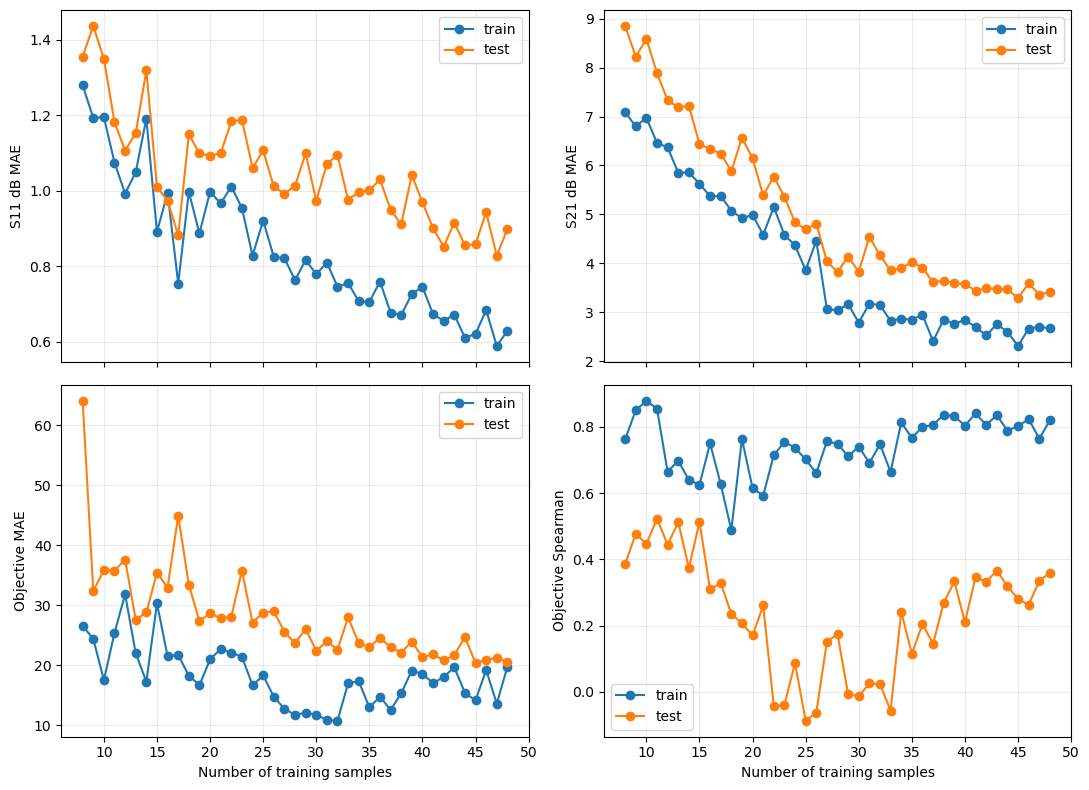

In [6]:
def metric_series(rows, split, metric):
    filtered = [row for row in rows if row["split"] == split]
    x = column(filtered, "num_train_samples")
    y = column(filtered, metric)
    return x, y

if metrics_rows:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
    for split in ["train", "test"]:
        x, y = metric_series(metrics_rows, split, "s11_db_mae")
        axes[0, 0].plot(x, y, marker="o", label=split)
        x, y = metric_series(metrics_rows, split, "s21_db_mae")
        axes[0, 1].plot(x, y, marker="o", label=split)
        x, y = metric_series(metrics_rows, split, "objective_mae")
        axes[1, 0].plot(x, y, marker="o", label=split)
        x, y = metric_series(metrics_rows, split, "objective_spearman")
        axes[1, 1].plot(x, y, marker="o", label=split)
    axes[0, 0].set_ylabel("S11 dB MAE")
    axes[0, 1].set_ylabel("S21 dB MAE")
    axes[1, 0].set_ylabel("Objective MAE")
    axes[1, 1].set_ylabel("Objective Spearman")
    for ax in axes[-1, :]:
        ax.set_xlabel("Number of training samples")
    for ax in axes.ravel():
        ax.grid(True, alpha=0.25)
        ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "fewshot_learning_curves.png", dpi=160)
    plt.show()


## Initial And Final Comparisons

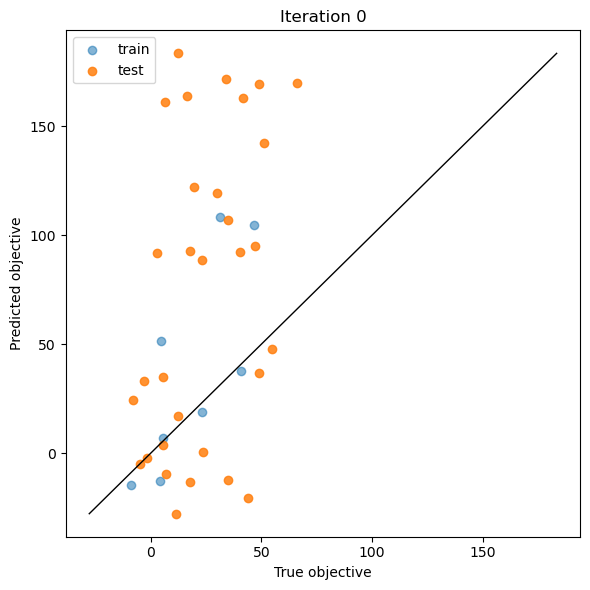

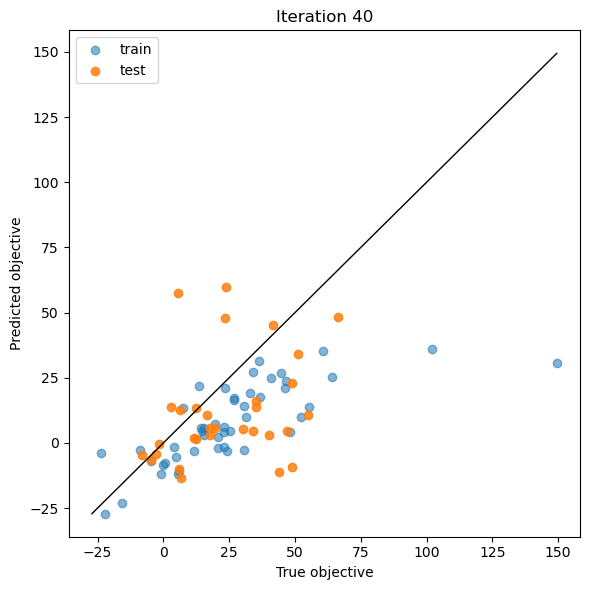

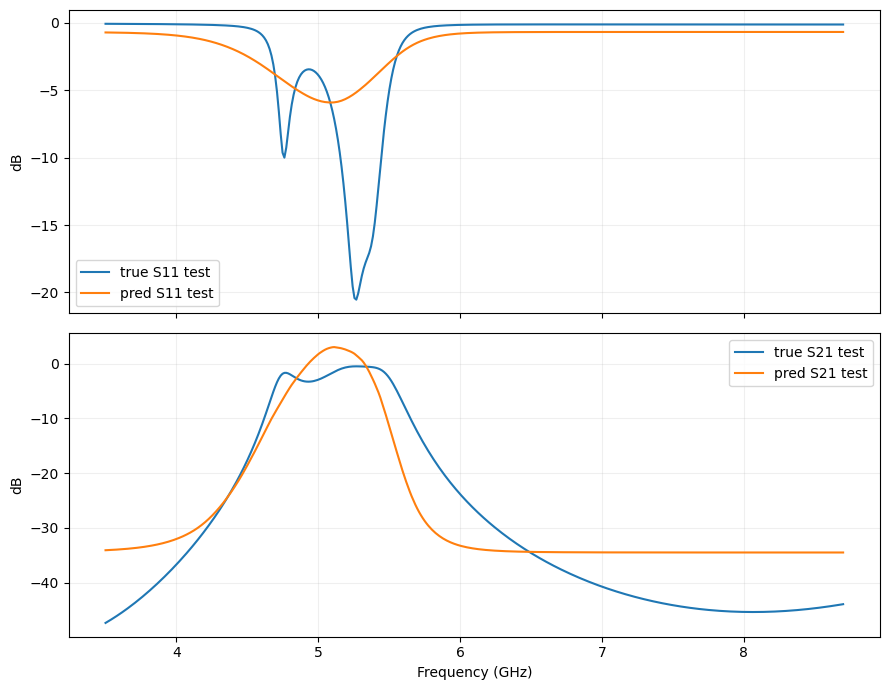

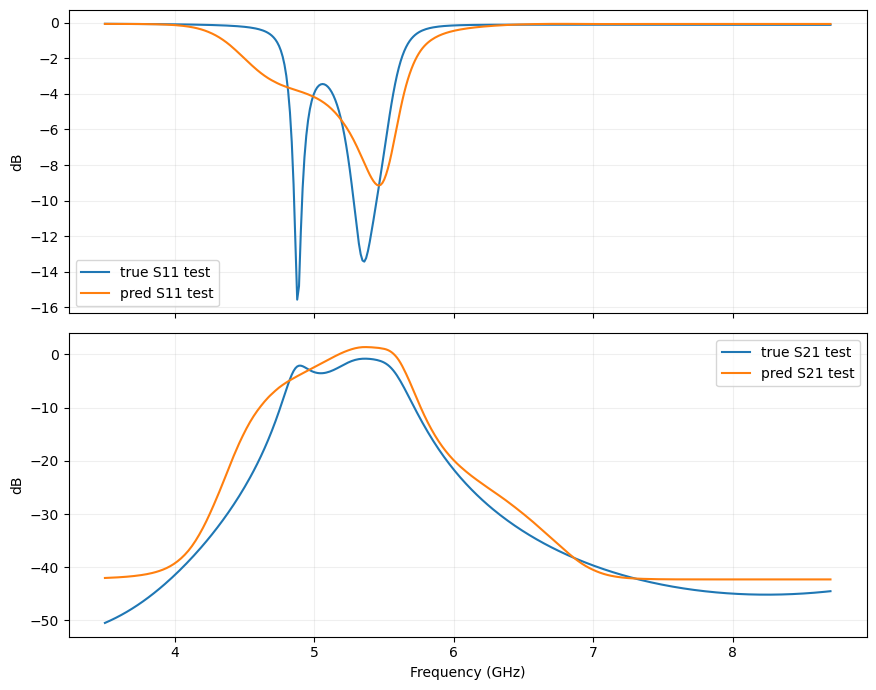

In [7]:
def rows_for_iteration(split, iteration):
    return [row for row in prediction_rows if row["split"] == split and int(row["iteration"]) == int(iteration)]


def plot_objective_scatter(iteration, filename):
    train_rows = rows_for_iteration("train", iteration)
    test_rows = rows_for_iteration("test", iteration)
    if not train_rows or not test_rows:
        return
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(column(train_rows, "true_objective"), column(train_rows, "pred_objective"), alpha=0.55, label="train")
    ax.scatter(column(test_rows, "true_objective"), column(test_rows, "pred_objective"), alpha=0.85, label="test")
    all_values = np.concatenate([
        column(train_rows, "true_objective"), column(train_rows, "pred_objective"),
        column(test_rows, "true_objective"), column(test_rows, "pred_objective"),
    ])
    lo = float(np.min(all_values))
    hi = float(np.max(all_values))
    ax.plot([lo, hi], [lo, hi], color="black", linewidth=1)
    ax.set_xlabel("True objective")
    ax.set_ylabel("Predicted objective")
    ax.set_title(f"Iteration {iteration}")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160)
    plt.show()


def plot_best_test_response(iteration, filename):
    rows = rows_for_iteration("test", iteration)
    if not rows:
        return
    local_pos = int(np.argmin(column(rows, "abs_objective_error")))
    indices = snapshots[f"iter{iteration}_test_indices"]
    pred_sparams = snapshots[f"iter{iteration}_test_pred_sparams"]
    dataset_idx = int(indices[local_pos])
    pred = pred_sparams[[local_pos]]
    true = dataset.s_params[[dataset_idx]]
    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    axes[0].plot(dataset.freqs / 1e9, response_db(true, 0, 0)[0], label="true S11 test")
    axes[0].plot(dataset.freqs / 1e9, response_db(pred, 0, 0)[0], label="pred S11 test")
    axes[1].plot(dataset.freqs / 1e9, response_db(true, 1, 0)[0], label="true S21 test")
    axes[1].plot(dataset.freqs / 1e9, response_db(pred, 1, 0)[0], label="pred S21 test")
    for ax in axes:
        ax.set_ylabel("dB")
        ax.legend()
        ax.grid(True, alpha=0.2)
    axes[-1].set_xlabel("Frequency (GHz)")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160)
    plt.show()

plot_objective_scatter(0, "fewshot_objective_scatter_initial.png")
plot_objective_scatter(num_updates, "fewshot_objective_scatter_final.png")
plot_best_test_response(0, "fewshot_test_response_initial.png")
plot_best_test_response(num_updates, "fewshot_test_response_final.png")
